In [1]:
import os
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, accuracy_score, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold

# ==============================================================================
# CONFIGURATION BLOCK (v3 Finalized & Standalone)
# ==============================================================================
CONFIG = {
    "tau_grid": np.linspace(0.05, 1.0, 30),
    "bootstrap_draws": 1000,
    "bootstrap_seed": 42,
    "random_seeds": range(5),  # Seeds 0-4
    "question": "Q3",
    "k": 0,
    "tag": "[Ours]",
    "audio_source": "default_npz"
}

print("1. Loading data files and inspecting structures...")
events_df = pd.read_csv("clip_events.csv")
summary_df = pd.read_csv("results_summary.csv")
npz_data = np.load("clip_probs.npz", allow_pickle=True)

exp_cam_acc = summary_df.loc[summary_df["model"] == "global_visual", "accuracy"].values[0]
exp_cam_f1 = summary_df.loc[summary_df["model"] == "global_visual", "macro_f1"].values[0]
exp_aud_acc = summary_df.loc[summary_df["model"] == "audio_only", "accuracy"].values[0]
exp_aud_f1 = summary_df.loc[summary_df["model"] == "audio_only", "macro_f1"].values[0]

video_names_npz = npz_data["video_name"]
splits = npz_data["split"]
classes = npz_data["classes"]
camera_probs = npz_data["camera"]
audio_probs = npz_data["audio"]

npz_df = pd.DataFrame({
    "video_name": video_names_npz,
    "split_npz": splits,
    "npz_idx": np.arange(len(video_names_npz))
})

merged_df = pd.merge(events_df, npz_df, on="video_name", how="inner")

# ------------------------------------------------------------------------------
# SPLIT HANDLING
# ------------------------------------------------------------------------------
if CONFIG["k"] == 0:
    target_df = merged_df[merged_df["split_npz"].isin(["adapt", "test"])].copy()
    split_label = "target_site_525"
    shift_level = "target_site_adapt_test"
else:
    target_df = merged_df[merged_df["split_npz"] == "test"].copy()
    split_label = "test_site_456"
    shift_level = "target_site_test_only"

indices = target_df["npz_idx"].values
y_raw = target_df["species"].values
site_ids = target_df["location_id"].values

camera_target = camera_probs[indices]
audio_target = audio_probs[indices]

class_to_idx = {cls: idx for idx, cls in enumerate(classes)}
y_true = np.array([class_to_idx[val] for val in y_raw])
n_classes = len(classes)
n_clips = len(y_true)
n_sites = len(np.unique(site_ids))

# ------------------------------------------------------------------------------
# HARD ASSERTS & BASELINE CHECKS
# ------------------------------------------------------------------------------
vis_preds_base = np.argmax(camera_target, axis=1)
aud_preds_base = np.argmax(audio_target, axis=1)

base_cam_acc = accuracy_score(y_true, vis_preds_base)
base_cam_f1 = f1_score(y_true, vis_preds_base, average="macro", labels=range(n_classes), zero_division=0)
base_aud_acc = accuracy_score(y_true, aud_preds_base)
base_aud_f1 = f1_score(y_true, aud_preds_base, average="macro", labels=range(n_classes), zero_division=0)

assert abs(base_cam_acc - exp_cam_acc) < 0.0001
assert abs(base_cam_f1 - exp_cam_f1) < 0.0001
assert abs(base_aud_acc - exp_aud_acc) < 0.0001
assert abs(base_aud_f1 - exp_aud_f1) < 0.0001
print("All M3 v1 Hard Asserts Passed Successfully!")

# ------------------------------------------------------------------------------
# SOURCE OOF FUSION & TAU TUNING
# ------------------------------------------------------------------------------
source_oof_df = merged_df[(merged_df["split_npz"] == "source") & (merged_df["cv_fold"] != -1) & (merged_df["prob_source"] == "oof_site_cv")].copy()
source_indices = source_oof_df["npz_idx"].values
source_y = np.array([class_to_idx[val] for val in source_oof_df["species"].values])
source_cam = camera_probs[source_indices]
source_aud = audio_probs[source_indices]

source_cam_log = np.log(np.clip(source_cam, 1e-8, 1.0))
source_aud_log = np.log(np.clip(source_aud, 1e-8, 1.0))
target_cam_log = np.log(np.clip(camera_target, 1e-8, 1.0))
target_aud_log = np.log(np.clip(audio_target, 1e-8, 1.0))

best_alpha = 0.5
best_f1 = -1.0
for alpha in np.linspace(0.0, 1.0, 101):
    blend_log = alpha * source_cam_log + (1 - alpha) * source_aud_log
    macro_f1 = f1_score(source_y, np.argmax(blend_log, axis=1), average="macro", labels=range(n_classes), zero_division=0)
    if macro_f1 > best_f1:
        best_f1 = macro_f1
        best_alpha = alpha

p_fusion_log = best_alpha * target_cam_log + (1 - best_alpha) * target_aud_log
fusion_preds = np.argmax(p_fusion_log, axis=1)
vis_conf = np.max(camera_target, axis=1)
source_vis_conf = np.max(source_cam, axis=1)
source_vis_preds = np.argmax(source_cam, axis=1)
source_fusion_preds = np.argmax(best_alpha * source_cam_log + (1 - best_alpha) * source_aud_log, axis=1)

best_tau = 0.5
best_tau_f1 = -1.0
for tau in CONFIG["tau_grid"]:
    defer_source = source_vis_conf < tau
    f1 = f1_score(source_y, np.where(defer_source, source_fusion_preds, source_vis_preds), average="macro", labels=range(n_classes), zero_division=0)
    if f1 > best_tau_f1:
        best_tau_f1 = f1
        best_tau = tau

audio_preds = aud_preds_base
oracle_sensor_preds = np.copy(vis_preds_base)
for i in range(len(y_true)):
    if vis_preds_base[i] != y_true[i] and audio_preds[i] == y_true[i]:
        oracle_sensor_preds[i] = audio_preds[i]

# ------------------------------------------------------------------------------
# EVALUATION & PAIRED BOOTSTRAP HARNESS
# ------------------------------------------------------------------------------
def evaluate_policy_detailed(defer_mask, fusion_preds, vis_preds, y_true, site_array):
    final_preds = np.where(defer_mask, fusion_preds, vis_preds)
    macro_f1 = f1_score(y_true, final_preds, average="macro", labels=range(n_classes), zero_division=0)
    acc = accuracy_score(y_true, final_preds)
    act_rate = np.mean(defer_mask)

    unique_sites = np.unique(site_array)
    boot_f1s = []
    rng = np.random.default_rng(CONFIG["bootstrap_seed"])
    for _ in range(CONFIG["bootstrap_draws"]):
        sampled_sites = rng.choice(unique_sites, size=len(unique_sites), replace=True)
        sampled_indices = np.concatenate([np.where(site_array == s)[0] for s in sampled_sites])
        if len(sampled_indices) > 0:
            boot_f1s.append(f1_score(y_true[sampled_indices], final_preds[sampled_indices], average="macro", labels=range(n_classes), zero_division=0))

    ci_low, ci_high = np.percentile(boot_f1s, [2.5, 97.5]) if boot_f1s else (macro_f1, macro_f1)
    return macro_f1, acc, act_rate, f"[{ci_low:.3f}, {ci_high:.3f}]"

def evaluate_paired_diff_bootstrap(final_preds_policy, final_preds_baseline, y_true, site_array):
    point_diff = f1_score(y_true, final_preds_policy, average="macro", labels=range(n_classes), zero_division=0) - f1_score(y_true, final_preds_baseline, average="macro", labels=range(n_classes), zero_division=0)
    unique_sites = np.unique(site_array)
    boot_diffs = []
    rng = np.random.default_rng(CONFIG["bootstrap_seed"])
    for _ in range(CONFIG["bootstrap_draws"]):
        sampled_sites = rng.choice(unique_sites, size=len(unique_sites), replace=True)
        sampled_indices = np.concatenate([np.where(site_array == s)[0] for s in sampled_sites])
        if len(sampled_indices) > 0:
            f1_p = f1_score(y_true[sampled_indices], final_preds_policy[sampled_indices], average="macro", labels=range(n_classes), zero_division=0)
            f1_b = f1_score(y_true[sampled_indices], final_preds_baseline[sampled_indices], average="macro", labels=range(n_classes), zero_division=0)
            boot_diffs.append(f1_p - f1_b)
    ci_low, ci_high = np.percentile(boot_diffs, [2.5, 97.5]) if boot_diffs else (point_diff, point_diff)
    return point_diff, f"[{ci_low:.3f}, {ci_high:.3f}]"

f1_vis, acc_vis, act_vis, ci_vis = evaluate_policy_detailed(np.zeros(len(y_true), dtype=bool), fusion_preds, vis_preds_base, y_true, site_ids)
f1_both, acc_both, act_both, ci_both = evaluate_policy_detailed(np.ones(len(y_true), dtype=bool), fusion_preds, vis_preds_base, y_true, site_ids)
f1_oracle, acc_oracle, act_oracle, ci_oracle = evaluate_policy_detailed(np.ones(len(y_true), dtype=bool), oracle_sensor_preds, vis_preds_base, y_true, site_ids)

defer_frozen_tau = vis_conf < best_tau
f1_tau, acc_tau, act_tau, ci_tau = evaluate_policy_detailed(defer_frozen_tau, fusion_preds, vis_preds_base, y_true, site_ids)

# ------------------------------------------------------------------------------
# LEARNED REJECTOR (GroupKFold CV AUC on Source OOF)
# ------------------------------------------------------------------------------
known_placements = sorted(source_oof_df["placement"].dropna().unique()) if "placement" in source_oof_df.columns else ["arboreal", "terrestrial", "unknown"]
def extract_pre_audio_features(cam_p_matrix, df_subset, known_placements):
    feats = []
    for i, (idx, row) in enumerate(df_subset.iterrows()):
        cp = cam_p_matrix[i]
        ordered = sorted(cp, reverse=True)
        entropy = -sum(q * np.log(max(q, 1e-8)) for q in cp)
        is_ir = float(row.get("is_ir", False) == True or row.get("is_ir") == "True")
        is_night = float(row.get("is_night", False) == True or row.get("is_night") == "True") if "is_night" in row else 0.0
        placement_feats = [float(row.get("placement") == val) for val in known_placements]
        feats.append(list(cp) + [entropy, ordered[0] - ordered[1], is_ir, is_night] + placement_feats)
    return np.array(feats)

source_target_oof = np.array([int(source_vis_preds[i] != source_y[i] and source_fusion_preds[i] == source_y[i]) for i in range(len(source_oof_df))])
source_feats = extract_pre_audio_features(source_cam, source_oof_df, known_placements)
source_sites = source_oof_df["location_id"].values

gkf = GroupKFold(n_splits=5)
source_rejector_oof_probs = np.zeros(len(source_oof_df))
for train_idx, val_idx in gkf.split(source_feats, source_target_oof, groups=source_sites):
    clf_fold = LogisticRegression(max_iter=1000, C=1.0)
    clf_fold.fit(source_feats[train_idx], source_target_oof[train_idx])
    source_rejector_oof_probs[val_idx] = clf_fold.predict_proba(source_feats[val_idx])[:, 1]

rejector_cv_auc = roc_auc_score(source_target_oof, source_rejector_oof_probs)

rejector_clf = LogisticRegression(max_iter=1000, C=1.0)
rejector_clf.fit(source_feats, source_target_oof)
target_rejector_probs = rejector_clf.predict_proba(extract_pre_audio_features(camera_target, target_df, known_placements))[:, 1]

best_rej_thresh = 0.5
best_rej_source_f1 = -1.0
for thresh in np.linspace(0.0, 1.0, 50):
    f1 = f1_score(source_y, np.where(source_rejector_oof_probs > thresh, source_fusion_preds, source_vis_preds), average="macro", labels=range(n_classes), zero_division=0)
    if f1 > best_rej_source_f1:
        best_rej_source_f1 = f1
        best_rej_thresh = thresh

defer_best_rej = target_rejector_probs > best_rej_thresh
f1_rej, acc_rej, act_rej, ci_rej = evaluate_policy_detailed(defer_best_rej, fusion_preds, vis_preds_base, y_true, site_ids)

# ------------------------------------------------------------------------------
# MEMBER 2 AVAILABILITY VARIANT QUANTILE SWEEP & TARGET AUC
# ------------------------------------------------------------------------------
avail_path = "availability.csv"
availability_sweep_results = []
avail_target_auc = float("nan")
auc_ci_low = auc_ci_high = float("nan")
target_usefulness_sum = 0

if os.path.exists(avail_path):
    avail_df = pd.read_csv(avail_path)
    target_avail_df = pd.merge(target_df, avail_df, on="video_name", how="inner", suffixes=("", "_avail"))
    assert len(target_avail_df) == n_clips
    assert target_avail_df["video_name"].is_unique

    availability_scores = target_avail_df["predicted_probability"].values
    target_usefulness = np.array([int(vis_preds_base[i] != y_true[i] and fusion_preds[i] == y_true[i]) for i in range(n_clips)])
    target_usefulness_sum = int(target_usefulness.sum())

    if target_usefulness_sum > 0 and target_usefulness_sum < n_clips:
        avail_target_auc = roc_auc_score(target_usefulness, availability_scores)
        rng_auc = np.random.default_rng(CONFIG["bootstrap_seed"])
        boot_aucs = []
        unique_sites = np.unique(site_ids)
        for _ in range(CONFIG["bootstrap_draws"]):
            sampled_sites = rng_auc.choice(unique_sites, size=len(unique_sites), replace=True)
            sampled_indices = np.concatenate([np.where(site_ids == s)[0] for s in sampled_sites])
            if len(np.unique(target_usefulness[sampled_indices])) > 1:
                boot_aucs.append(roc_auc_score(target_usefulness[sampled_indices], availability_scores[sampled_indices]))
        auc_ci_low, auc_ci_high = np.percentile(boot_aucs, [2.5, 97.5]) if boot_aucs else (avail_target_auc, avail_target_auc)

    for target_act in [0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50, 0.60, 0.80, 1.0]:
        thresh = np.percentile(availability_scores, 100 * (1.0 - target_act))
        defer_mask = availability_scores >= thresh
        final_preds = np.where(defer_mask, fusion_preds, vis_preds_base)
        f1, acc, act_rate, ci = evaluate_policy_detailed(defer_mask, fusion_preds, vis_preds_base, y_true, site_ids)
        _, diff_vis_ci = evaluate_paired_diff_bootstrap(final_preds, vis_preds_base, y_true, site_ids)
        _, diff_both_ci = evaluate_paired_diff_bootstrap(final_preds, fusion_preds, y_true, site_ids)
        availability_sweep_results.append({
            "target_act": target_act, "threshold": thresh, "f1": f1, "acc": acc, "act_rate": act_rate, "ci": ci,
            "diff_vis_ci": diff_vis_ci, "diff_both_ci": diff_both_ci
        })

# Precompute sweep results for Cell 2 plotting
sweep_results = []
for tau in CONFIG["tau_grid"]:
    defer = vis_conf < tau
    f1, acc, act, ci = evaluate_policy_detailed(defer, fusion_preds, vis_preds_base, y_true, site_ids)
    sweep_results.append({"tau": tau, "f1": f1, "acc": acc, "act": act, "ci": ci})

rand_results = []
for res in sweep_results:
    target_act = res["act"]
    seed_f1s = []
    for seed in CONFIG["random_seeds"]:
        rng_seed = np.random.default_rng(seed)
        rand_defer = rng_seed.random(len(y_true)) < target_act
        f1_r, _, _, _ = evaluate_policy_detailed(rand_defer, fusion_preds, vis_preds_base, y_true, site_ids)
        seed_f1s.append(f1_r)
    rand_results.append({"act": target_act, "f1": np.mean(seed_f1s)})

# ------------------------------------------------------------------------------
# HEADLINE PRINT BLOCK
# ------------------------------------------------------------------------------
print("\n" + "="*60)
print(f" SA-FARI v2 EVALUATION SUMMARY ({split_label})")
print("="*60)
print(f" Always-Visual (Camera Only) F1 : {f1_vis:.4f}  | Acc: {acc_vis:.4f}")
print(f" Always-Both (Visual + Audio) F1  : {f1_both:.4f}  | Acc: {acc_both:.4f}")
print(f" Tuned Tau Selector (tau={best_tau:.2f}) F1 : {f1_tau:.4f}  | Audio Used: {act_tau*100:.1f}%")
print(f" Learned Rejector CV ROC-AUC     : {rejector_cv_auc:.4f}")
print(f" Availability Target ROC-AUC     : {avail_target_auc:.4f} (CI: [{auc_ci_low:.3f}, {auc_ci_high:.3f}], Useful Clips: {target_usefulness_sum})")
print("-"*60)
print(" Availability Quantile Sweep Highlights:")
for res in availability_sweep_results[::2]: # print every alternate point
    print(f"   Target Act: {res['target_act']*100:3.0f}% | Actual: {res['act_rate']*100:4.1f}% | F1: {res['f1']:.4f} | Diff vs Both CI: {res['diff_both_ci']}")
print("="*60 + "\n")

# ------------------------------------------------------------------------------
# LOGGING RESULTS (With fixed scrub name & additional metric logs)
# ------------------------------------------------------------------------------
log_path = "results_log.csv"
current_experiment_names = [
    f"baseline_always_visual_{split_label}_v2",
    f"baseline_always_both_{split_label}_v2",
    f"oracle_sensor_choice_{split_label}_v2",
    f"source_oof_tuned_tau_{split_label}_v2", # Fixed constant name
    f"learned_rejector_{split_label}_v2",
    f"learned_rejector_cv_{split_label}_v2",
    f"availability_target_evaluation_{split_label}_v2"
]
for res in sweep_results: current_experiment_names.append(f"conf_threshold_{res['tau']:.2f}_{split_label}_v2")
for res in availability_sweep_results: current_experiment_names.append(f"availability_quantile_{res['target_act']:.2f}_{split_label}_v2")

new_rows = [
    {"experiment": f"baseline_always_visual_{split_label}_v2", "question": CONFIG["question"], "metric": "macro_f1", "value": round(f1_vis, 4), "interval": ci_vis, "number of events": n_clips, "shift level": shift_level, "k": CONFIG["k"], "tag": CONFIG["tag"], "accuracy": round(acc_vis, 4), "audio_used_rate": 0.0, "compute_proxy": 0.0},
    {"experiment": f"baseline_always_both_{split_label}_v2", "question": CONFIG["question"], "metric": "macro_f1", "value": round(f1_both, 4), "interval": ci_both, "number of events": n_clips, "shift level": shift_level, "k": CONFIG["k"], "tag": CONFIG["tag"], "accuracy": round(acc_both, 4), "audio_used_rate": 1.0, "compute_proxy": 1.0},
    {"experiment": f"oracle_sensor_choice_{split_label}_v2", "question": CONFIG["question"], "metric": "macro_f1", "value": round(f1_oracle, 4), "interval": ci_oracle, "number of events": n_clips, "shift level": shift_level, "k": CONFIG["k"], "tag": CONFIG["tag"], "accuracy": round(acc_oracle, 4), "audio_used_rate": 1.0, "compute_proxy": 1.0},
    {"experiment": f"source_oof_tuned_tau_{split_label}_v2", "question": CONFIG["question"], "metric": "macro_f1", "value": round(f1_tau, 4), "interval": ci_tau, "number of events": n_clips, "shift level": shift_level, "k": CONFIG["k"], "tag": CONFIG["tag"], "accuracy": round(acc_tau, 4), "audio_used_rate": round(act_tau, 4), "compute_proxy": round(act_tau, 4), "threshold": best_tau},
    {"experiment": f"learned_rejector_{split_label}_v2", "question": CONFIG["question"], "metric": "macro_f1", "value": round(f1_rej, 4), "interval": ci_rej, "number of events": n_clips, "shift level": shift_level, "k": CONFIG["k"], "tag": CONFIG["tag"], "accuracy": round(acc_rej, 4), "audio_used_rate": round(act_rej, 4), "compute_proxy": round(act_rej, 4)},
    {"experiment": f"learned_rejector_cv_{split_label}_v2", "question": CONFIG["question"], "metric": "roc_auc", "value": round(rejector_cv_auc, 4), "interval": "[0.000, 0.000]", "number of events": n_clips, "shift level": shift_level, "k": CONFIG["k"], "tag": CONFIG["tag"], "accuracy": 0.0, "audio_used_rate": 0.0, "compute_proxy": 0.0},
    {"experiment": f"availability_target_evaluation_{split_label}_v2", "question": CONFIG["question"], "metric": "roc_auc", "value": round(avail_target_auc, 4), "interval": f"[{auc_ci_low:.3f}, {auc_ci_high:.3f}]", "number of events": target_usefulness_sum, "shift level": shift_level, "k": CONFIG["k"], "tag": CONFIG["tag"], "accuracy": 0.0, "audio_used_rate": 0.0, "compute_proxy": 0.0}
]

for res in sweep_results:
    new_rows.append({"experiment": f"conf_threshold_{res['tau']:.2f}_{split_label}_v2", "question": CONFIG["question"], "metric": "macro_f1", "value": round(res["f1"], 4), "interval": res["ci"], "number of events": n_clips, "shift level": shift_level, "k": CONFIG["k"], "tag": CONFIG["tag"], "accuracy": round(res["acc"], 4), "audio_used_rate": round(res["act"], 4), "compute_proxy": round(res["act"], 4)})

for res in availability_sweep_results:
    ta = res["target_act"]
    new_rows.append({"experiment": f"availability_quantile_{ta:.2f}_{split_label}_v2", "question": CONFIG["question"], "metric": "macro_f1", "value": round(res["f1"], 4), "interval": res["ci"], "number of events": n_clips, "shift level": shift_level, "k": CONFIG["k"], "tag": CONFIG["tag"], "accuracy": round(res["acc"], 4), "audio_used_rate": round(res["act_rate"], 4), "compute_proxy": round(res["act_rate"], 4)})
    new_rows.append({"experiment": f"availability_quantile_{ta:.2f}_{split_label}_v2", "question": CONFIG["question"], "metric": "macro_f1_diff_vs_visual", "value": round(res["f1"] - f1_vis, 4), "interval": res["diff_vis_ci"], "number of events": n_clips, "shift level": shift_level, "k": CONFIG["k"], "tag": CONFIG["tag"], "accuracy": round(res["acc"], 4), "audio_used_rate": round(res["act_rate"], 4), "compute_proxy": round(res["act_rate"], 4)})
    new_rows.append({"experiment": f"availability_quantile_{ta:.2f}_{split_label}_v2", "question": CONFIG["question"], "metric": "macro_f1_diff_vs_both", "value": round(res["f1"] - f1_both, 4), "interval": res["diff_both_ci"], "number of events": n_clips, "shift level": shift_level, "k": CONFIG["k"], "tag": CONFIG["tag"], "accuracy": round(res["acc"], 4), "audio_used_rate": round(res["act_rate"], 4), "compute_proxy": round(res["act_rate"], 4)})

new_df = pd.DataFrame(new_rows)
if os.path.exists(log_path):
    old_df = pd.read_csv(log_path)
    if "experiment" in old_df.columns:
        old_df = old_df[~old_df["experiment"].isin(current_experiment_names)]
    combined_df = pd.concat([old_df, new_df], ignore_index=True)
else:
    combined_df = new_df

subset_cols = [c for c in ["experiment", "metric", "shift level", "k"] if c in combined_df.columns]
combined_df = combined_df.drop_duplicates(subset=subset_cols, keep="last")
combined_df.to_csv(log_path, index=False)
print(f"Successfully evaluated and logged v2 results to {log_path}!")

1. Loading data files and inspecting structures...
All M3 v1 Hard Asserts Passed Successfully!

 SA-FARI v2 EVALUATION SUMMARY (target_site_525)
 Always-Visual (Camera Only) F1 : 0.4783  | Acc: 0.5238
 Always-Both (Visual + Audio) F1  : 0.4857  | Acc: 0.5371
 Tuned Tau Selector (tau=0.64) F1 : 0.4869  | Audio Used: 63.6%
 Learned Rejector CV ROC-AUC     : 0.7747
 Availability Target ROC-AUC     : 0.7466 (CI: [0.622, 0.875], Useful Clips: 19)
------------------------------------------------------------
 Availability Quantile Sweep Highlights:
   Target Act:   5% | Actual:  5.1% | F1: 0.4835 | Diff vs Both CI: [-0.020, 0.017]
   Target Act:  15% | Actual: 15.0% | F1: 0.4857 | Diff vs Both CI: [-0.016, 0.016]
   Target Act:  30% | Actual: 30.1% | F1: 0.4878 | Diff vs Both CI: [-0.010, 0.013]
   Target Act:  50% | Actual: 50.1% | F1: 0.4835 | Diff vs Both CI: [-0.010, 0.005]
   Target Act:  80% | Actual: 80.0% | F1: 0.4857 | Diff vs Both CI: [0.000, 0.000]

Successfully evaluated and logge

Generating v2 Pareto Curve Plot...


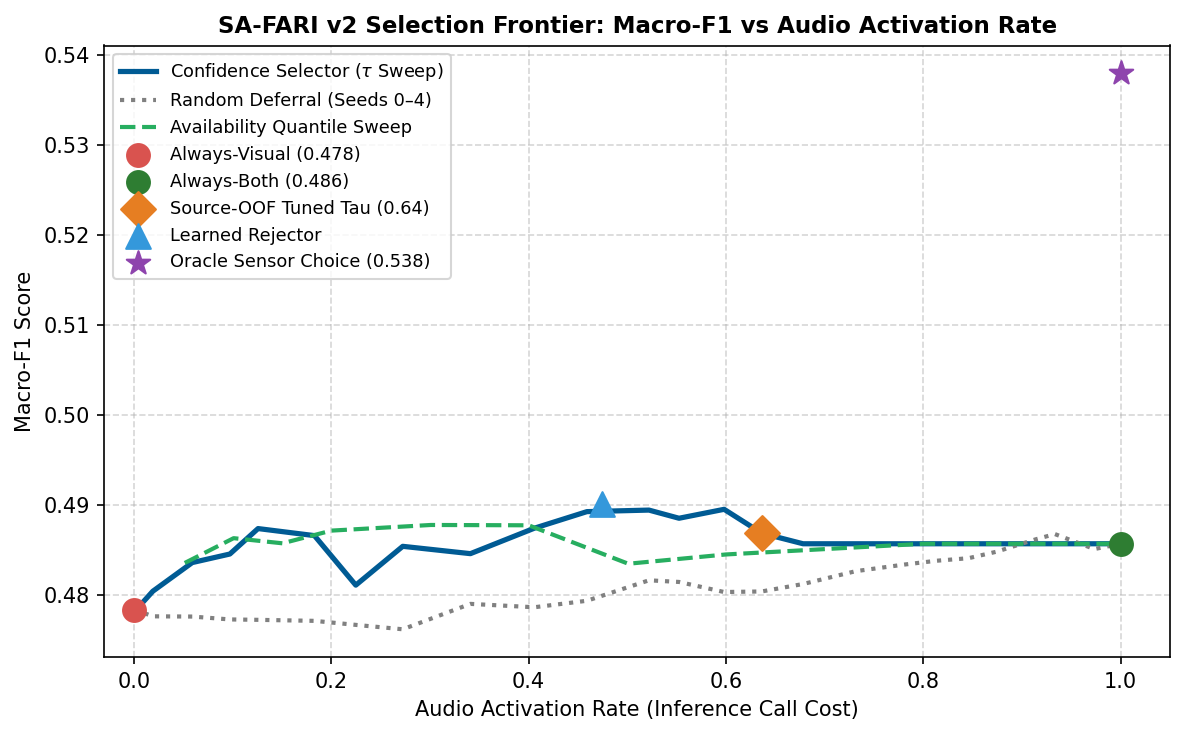

Pareto curve generated and saved successfully to results/selector_pareto_curve_v2.png!


In [2]:
import os
import matplotlib.pyplot as plt

print("Generating v2 Pareto Curve Plot...")
fig, ax = plt.subplots(figsize=(8, 5), dpi=150)

tau_acts = [r["act"] for r in sweep_results]
tau_f1s = [r["f1"] for r in sweep_results]

ax.plot(tau_acts, tau_f1s, color="#005B94", lw=2.5, label=r"Confidence Selector ($\tau$ Sweep)")
ax.plot([r["act"] for r in rand_results], [r["f1"] for r in rand_results], color="gray", linestyle=":", lw=2, label="Random Deferral (Seeds 0–4)")

if availability_sweep_results:
    ax.plot([r["act_rate"] for r in availability_sweep_results], [r["f1"] for r in availability_sweep_results], color="#27AE60", lw=2, linestyle="--", label="Availability Quantile Sweep")

ax.scatter([0.0], [f1_vis], color="#D9534F", s=120, zorder=5, label=f"Always-Visual ({f1_vis:.3f})")
ax.scatter([1.0], [f1_both], color="#2E7D32", s=120, zorder=5, label=f"Always-Both ({f1_both:.3f})")
ax.scatter([act_tau], [f1_tau], color="#E67E22", s=140, marker="D", zorder=6, label=f"Source-OOF Tuned Tau ({best_tau:.2f})")
ax.scatter([act_rej], [f1_rej], color="#3498DB", s=140, marker="^", zorder=6, label="Learned Rejector")
ax.scatter([1.0], [f1_oracle], color="#8E44AD", s=140, marker="*", zorder=5, label=f"Oracle Sensor Choice ({f1_oracle:.3f})")

ax.set_title("SA-FARI v2 Selection Frontier: Macro-F1 vs Audio Activation Rate", fontsize=11, fontweight="bold")
ax.set_xlabel("Audio Activation Rate (Inference Call Cost)", fontsize=10)
ax.set_ylabel("Macro-F1 Score", fontsize=10)
ax.set_xlim(-0.03, 1.05)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="upper left", fontsize=8.5)

os.makedirs("results", exist_ok=True)
plt.tight_layout()
plt.savefig("results/selector_pareto_curve_v2.png", dpi=300, bbox_inches="tight")
plt.show()
print("Pareto curve generated and saved successfully to results/selector_pareto_curve_v2.png!")

In [3]:
# =============================================================================
# FINAL CELL (Member 4): Q3 at k=1,3 | Q2 recalibration | condition slices | AUC diagnostics
# Run AFTER the v2 cell, in the SAME kernel (it reuses the v2 variables and functions).
# Needs in the working directory: adapted_probs.npz (unzipped), adapt_draws.csv,
# and optionally adapted_results.csv and results_slices.csv (used only as cross-checks).
# =============================================================================
import os, shutil, time
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

# ------------------------------- configuration -------------------------------
FIN = {
    "k_list": [1, 3],                 # label budgets (labelled clips per species)
    "seeds": [0, 1, 2, 3, 4],         # same seeds as the rest of the team
    "budgets": [0.20, 0.30],          # fixed audio budgets for rank-based selectors
    "primary": "avail_b30",           # selector fixed IN ADVANCE for the Q3 decomposition (M2's primary budget)
    "draws": CONFIG["bootstrap_draws"],
    "boot_seed": CONFIG["bootstrap_seed"],
    "adapted_npz": "adapted_probs.npz",
    "draws_csv": "adapt_draws.csv",
    "adapted_results_csv": "adapted_results.csv",
    "slices_csv": "results_slices.csv",
    "min_clips": 30, "min_sites": 5,  # slices below this are flagged LOW_N (no conclusions)
}

# ------------------------------- sanity: v2 state ----------------------------
needed = ["CONFIG", "target_df", "y_true", "site_ids", "n_classes", "n_clips", "classes", "camera_target",
          "audio_target", "vis_preds_base", "aud_preds_base", "fusion_preds", "oracle_sensor_preds", "vis_conf",
          "best_alpha", "best_tau", "best_rej_thresh", "rejector_clf", "extract_pre_audio_features",
          "known_placements", "target_rejector_probs", "source_rejector_oof_probs", "source_target_oof",
          "source_vis_conf", "availability_scores", "avail_df", "source_oof_df", "log_path", "f1_vis",
          "rejector_cv_auc"]
missing = [v for v in needed if v not in globals()]
assert not missing, f"Run the v2 cell first. Missing variables: {missing}"
assert CONFIG["k"] == 0 and n_clips == 525, "The v2 cell must have been run with k=0 on the 525 target clips"
SPLIT_TAG = "target_site_525"

# ------------------------------- fast metrics --------------------------------
# Same definition as the team: macro-F1 over ALL n_classes, absent classes count as 0
def f1_fast(y, p):
    tp = np.bincount(y[y == p], minlength=n_classes)
    pc = np.bincount(p, minlength=n_classes)
    tc = np.bincount(y, minlength=n_classes)
    den = pc + tc
    return float(np.where(den > 0, 2.0 * tp / np.maximum(den, 1), 0.0).mean())

def acc_fast(y, p):
    return float(np.mean(y == p))

assert abs(f1_fast(y_true, vis_preds_base) - f1_vis) < 1e-9, "fast macro-F1 differs from sklearn"

# ------------------------------- bootstrap engine ----------------------------
def boot_eval(arms, masks, contrasts, metric, sites_arr):
    """
    arms:      {name: preds array (n_clips,) OR {seed: preds array}}
    masks:     {seed: bool mask of the clips to evaluate on}
    contrasts: {name: [(arm, coef), ...]}  (linear combinations, e.g. A - B)
    Each bootstrap draw resamples SITES once; the metric is computed per seed on the
    resampled eval clips and averaged over seeds, so all arms/contrasts share the same resample (paired).
    Returns {"arm": {name: (point, lo, hi, seed_min, seed_max)}, "con": {name: (point, lo, hi)}}.
    """
    fn = f1_fast if metric == "macro_f1" else acc_fast
    seeds = sorted(masks)
    names = list(arms)
    A = {n: {s: (arms[n][s] if isinstance(arms[n], dict) else arms[n]) for s in seeds} for n in names}
    M = {s: np.asarray(masks[s], bool) for s in seeds}
    union = np.logical_or.reduce([M[s] for s in seeds])
    if union.sum() == 0:
        return None
    sites = np.unique(sites_arr[union])
    site_idx = [np.where(sites_arr == u)[0] for u in sites]

    def metric_all(idx_by_seed):
        per = {n: [] for n in names}
        for s in seeds:
            ix = idx_by_seed[s]
            if len(ix) == 0:
                continue
            yy = y_true[ix]
            for n in names:
                per[n].append(fn(yy, A[n][s][ix]))
        return per

    per_pt = metric_all({s: np.where(M[s])[0] for s in seeds})
    pt = {n: float(np.mean(v)) for n, v in per_pt.items()}
    rng = np.random.default_rng(FIN["boot_seed"])
    boot = {n: [] for n in names}
    for _ in range(FIN["draws"]):
        pick = np.concatenate([site_idx[i] for i in rng.integers(0, len(sites), len(sites))])
        per = metric_all({s: pick[M[s][pick]] for s in seeds})
        for n in names:
            boot[n].append(np.mean(per[n]) if per[n] else np.nan)
    boot = {n: np.array(v) for n, v in boot.items()}

    out = {"arm": {}, "con": {}}
    for n in names:
        out["arm"][n] = (pt[n], float(np.nanpercentile(boot[n], 2.5)), float(np.nanpercentile(boot[n], 97.5)),
                         float(np.min(per_pt[n])), float(np.max(per_pt[n])))
    for c, terms in contrasts.items():
        p = sum(coef * pt[a] for a, coef in terms)
        b = sum(coef * boot[a] for a, coef in terms)
        out["con"][c] = (float(p), float(np.nanpercentile(b, 2.5)), float(np.nanpercentile(b, 97.5)))
    return out

fmt = lambda lo, hi: f"[{lo:.3f}, {hi:.3f}]"

# ------------------------------- helpers -------------------------------------
def rank_mask(score, frac, high_defers):
    """Defer exactly the top (high_defers=True) or bottom `frac` of clips by score (uses NO labels)."""
    m = int(round(frac * len(score)))
    order = np.argsort(-score if high_defers else score, kind="stable")
    mask = np.zeros(len(score), bool)
    mask[order[:m]] = True
    return mask

def fuse(cam, aud):
    """Log-probability fusion with the weight fitted on source OOF in the v2 cell (not refit for adapted experts)."""
    lc = np.log(np.clip(cam, 1e-8, 1.0)); la = np.log(np.clip(aud, 1e-8, 1.0))
    return np.argmax(best_alpha * lc + (1 - best_alpha) * la, axis=1)

def policy_masks(cam):
    """Defer masks for every selector, using PRE-AUDIO information only. `cam` = camera probabilities."""
    conf = cam.max(axis=1)
    rej = rejector_clf.predict_proba(extract_pre_audio_features(cam, target_df, known_placements))[:, 1]
    out = {"tau_src": conf < best_tau,                      # tau tuned on source OOF
           "rejector_src": rej > best_rej_thresh}           # threshold tuned on source OOF
    for b in FIN["budgets"]:
        out[f"conf_b{int(b*100)}"] = rank_mask(conf, b, False)                    # least-confident b of clips
        out[f"avail_b{int(b*100)}"] = rank_mask(availability_scores, b, True)     # highest M2 availability score
    return out

assert np.array_equal(fuse(camera_target, audio_target), fusion_preds), "fuse() does not reproduce v2 fusion"
POLICIES = list(policy_masks(camera_target).keys())
assert FIN["primary"] in POLICIES

rows = []
def add_row(exp, metric, value, interval, n, k, qlabel, shift, acc="", rate="", tag=None):
    rows.append({"experiment": "m4_" + exp.replace("|", "__"), "question": qlabel, "metric": metric,
                 "value": round(float(value), 4), "interval": interval, "number of events": int(n),
                 "shift level": shift, "k": k, "tag": tag or CONFIG["tag"],
                 "accuracy": acc if acc == "" else round(float(acc), 4),
                 "audio_used_rate": rate if rate == "" else round(float(rate), 4),
                 "compute_proxy": rate if rate == "" else round(float(rate), 4)})  # proxy = audio-used rate (no AST timings exist)

def log_result(prefix, k, qlabel, shift, res_f1, res_acc, rates, n_mean):
    for n, (p, lo, hi, _, _) in res_f1["arm"].items():
        add_row(f"{prefix}_{n}", "macro_f1", p, fmt(lo, hi), n_mean, k, qlabel, shift,
                acc=res_acc["arm"][n][0], rate=rates.get(n, ""))
    for c, (p, lo, hi) in res_f1["con"].items():
        add_row(f"{prefix}_{c}", "macro_f1_diff", p, fmt(lo, hi), n_mean, k, qlabel, shift)
    for c, (p, lo, hi) in res_acc["con"].items():
        add_row(f"{prefix}_{c}", "accuracy_diff", p, fmt(lo, hi), n_mean, k, qlabel, shift)

# ============================ 1. LOAD ADAPTED EXPERTS (M3 / M2) ================
ad = np.load(FIN["adapted_npz"], allow_pickle=True)
print("adapted_probs.npz keys (first 8):", list(ad.keys())[:8], "...")
pos = {v: i for i, v in enumerate(ad["video_name"])}
assert set(target_df["video_name"]) <= set(pos), "adapted npz is missing target clips"
order = np.array([pos[v] for v in target_df["video_name"].values])   # align to target_df row order
assert np.array_equal(ad["classes"], classes), "class order differs between adapted npz and clip_probs.npz"
draws_df = pd.read_csv(FIN["draws_csv"])

def load_k(k, s):
    cam = ad[f"camera_k{k}_s{s}"][order]; aud = ad[f"audio_k{k}_s{s}"][order]
    ev = ad[f"eval_k{k}_s{s}"][order].astype(bool)
    drawn = set(draws_df[(draws_df["k"] == k) & (draws_df["seed"] == s)]["video_name"])
    assert set(target_df["video_name"].values[~ev]) == drawn, f"eval mask != adapt_draws.csv (k={k}, seed={s})"
    return cam, aud, ev

LOADED = {(k, s): load_k(k, s) for k in FIN["k_list"] for s in FIN["seeds"]}
print("Adapted files loaded and aligned; eval masks match adapt_draws.csv for all k, seeds.")

# ============================ 2. Q3 AT k = 1, 3 ===============================
# Arms (all evaluated on the unlabelled clips of each seed, same clips for every arm):
#   vis_g / vis_a        camera only, global / adapted
#   both_g / both_a      always-both (fusion on every clip)
#   oracle_g / oracle_a  sensor-choice oracle
#   sel_g|P              global experts + selector P   (selector sees global camera features)
#   sel_a|P              adapted experts + selector P  (selector sees adapted camera features)
#   rand_*|P             random deferral at the same audio-use rate as selector P (paired uniform draws)
# Decomposition per selector P (all F1 differences, paired site bootstrap):
#   adapt_gain = vis_a - vis_g ;  select_gain = sel_g - vis_g ;  combined_gain = sel_a - vis_g
#   interaction = combined - adapt - select = (sel_a - vis_a) - (sel_g - vis_g)
#   interaction ~ 0 -> gains add up; < 0 -> redundant (sub-additive); > 0 -> complementary (super-additive)
Q3 = {}
mg = policy_masks(camera_target)
for k in FIN["k_list"]:
    t0 = time.time()
    arms, masks, rate_acc = {}, {}, {}
    def put(name, s, arr): arms.setdefault(name, {})[s] = arr
    def rec(name, mask, ev): rate_acc.setdefault(name, []).append(float(mask[ev].mean()))
    arms["vis_g"], arms["both_g"], arms["oracle_g"] = vis_preds_base, fusion_preds, oracle_sensor_preds
    for P in POLICIES:
        arms[f"sel_g|{P}"] = np.where(mg[P], fusion_preds, vis_preds_base)
    for s in FIN["seeds"]:
        cam_a, aud_a, ev = LOADED[(k, s)]
        masks[s] = ev
        va, aa, fa = cam_a.argmax(1), aud_a.argmax(1), fuse(cam_a, aud_a)
        orc = np.where((va != y_true) & (aa == y_true), aa, va)
        put("vis_a", s, va); put("both_a", s, fa); put("oracle_a", s, orc)
        ma = policy_masks(cam_a)
        u = np.random.default_rng(s).random(n_clips)       # one uniform draw per seed shared by the random arms
        for P in POLICIES:
            put(f"sel_a|{P}", s, np.where(ma[P], fa, va))
            rm_g, rm_a = u < mg[P].mean(), u < ma[P].mean()
            put(f"rand_g|{P}", s, np.where(rm_g, fusion_preds, vis_preds_base))
            put(f"rand_a|{P}", s, np.where(rm_a, fa, va))
            rec(f"sel_g|{P}", mg[P], ev); rec(f"sel_a|{P}", ma[P], ev)
            rec(f"rand_g|{P}", rm_g, ev); rec(f"rand_a|{P}", rm_a, ev)
    rates = {n: float(np.mean(v)) for n, v in rate_acc.items()}
    rates.update({"vis_g": 0.0, "vis_a": 0.0, "both_g": 1.0, "both_a": 1.0, "oracle_g": 1.0, "oracle_a": 1.0})

    con = {"adapt_gain": [("vis_a", 1), ("vis_g", -1)],
           "both_a_minus_vis_a": [("both_a", 1), ("vis_a", -1)],
           "oracle_a_minus_vis_a": [("oracle_a", 1), ("vis_a", -1)]}
    for P in POLICIES:
        con[f"select_gain|{P}"] = [(f"sel_g|{P}", 1), (f"vis_g", -1)]
        con[f"combined_gain|{P}"] = [(f"sel_a|{P}", 1), ("vis_g", -1)]
        con[f"interaction|{P}"] = [(f"sel_a|{P}", 1), ("vis_a", -1), (f"sel_g|{P}", -1), ("vis_g", 1)]
        con[f"select_gain_on_adapted|{P}"] = [(f"sel_a|{P}", 1), ("vis_a", -1)]
        con[f"sel_a_minus_both_a|{P}"] = [(f"sel_a|{P}", 1), ("both_a", -1)]   # one-pager check (a), adapted
        con[f"sel_g_minus_both_g|{P}"] = [(f"sel_g|{P}", 1), ("both_g", -1)]   # one-pager check (a), global
        con[f"sel_a_minus_rand_a|{P}"] = [(f"sel_a|{P}", 1), (f"rand_a|{P}", -1)]
        con[f"sel_g_minus_rand_g|{P}"] = [(f"sel_g|{P}", 1), (f"rand_g|{P}", -1)]

    r_f1 = boot_eval(arms, masks, con, "macro_f1", site_ids)
    r_ac = boot_eval(arms, masks, con, "accuracy", site_ids)
    Q3[k] = {"arms": arms, "masks": masks, "f1": r_f1, "acc": r_ac, "rates": rates}
    n_mean = int(np.mean([m.sum() for m in masks.values()]))
    log_result(f"q3_k{k}", k, "Q3", "target_site_eval_clips", r_f1, r_ac, rates, n_mean)

    # ---- check against M3's adapted_results.csv (camera macro-F1, global and adapted) ----
    if os.path.exists(FIN["adapted_results_csv"]):
        ar = pd.read_csv(FIN["adapted_results_csv"])
        r = ar[(ar.sensor == "camera") & (ar.k == k) & (ar.clip_set == "all_unlabelled") & (ar.metric == "macro_f1")]
        if len(r):
            dg = abs(r["global"].iloc[0] - r_f1["arm"]["vis_g"][0]); da = abs(r["adapted"].iloc[0] - r_f1["arm"]["vis_a"][0])
            print(f"[check] k={k} camera macro-F1 vs M3: global diff {dg:.4f}, adapted diff {da:.4f}",
                  "OK" if max(dg, da) < 0.01 else "<-- MISMATCH, check definitions")

    # ---- print ----
    print(f"\n===== Q3, k={k}  (eval clips ~{n_mean}, seeds {FIN['seeds']}, {time.time()-t0:.0f}s) =====")
    for n in ["vis_g", "vis_a", "both_g", "both_a", "oracle_g", "oracle_a"]:
        p, lo, hi, smin, smax = r_f1["arm"][n]
        print(f"  {n:10s} F1 {p:.4f} {fmt(lo, hi)}  seed range [{smin:.3f}, {smax:.3f}]  acc {r_ac['arm'][n][0]:.4f}")
    c = r_f1["con"]
    print(f"  adapt_gain (vis_a - vis_g): {c['adapt_gain'][0]:+.4f} {fmt(*c['adapt_gain'][1:])}")
    print(f"  {'selector':14s} {'audio':>6s} {'select_gain':>26s} {'combined_gain':>26s} {'interaction':>26s}")
    for P in POLICIES:
        sg, cg, it = c[f"select_gain|{P}"], c[f"combined_gain|{P}"], c[f"interaction|{P}"]
        tag = "  <-- PRIMARY" if P == FIN["primary"] else ""
        print(f"  {P:14s} {rates[f'sel_a|{P}']*100:5.1f}% {sg[0]:+.4f} {fmt(*sg[1:]):>17s} {cg[0]:+.4f} {fmt(*cg[1:]):>17s} "
              f"{it[0]:+.4f} {fmt(*it[1:]):>17s}{tag}")
    pr = FIN["primary"]; it = c[f"interaction|{pr}"]
    verdict = ("redundant (combined gain is smaller than the sum)" if it[2] < 0 else
               "complementary (combined gain exceeds the sum)" if it[1] > 0 else
               "no evidence either way: interval includes 0")
    print(f"  PRIMARY ({pr}) interaction {it[0]:+.4f} {fmt(*it[1:])} -> {verdict}")
    for P in POLICIES:   # one-pager check (a): match always-both at lower audio use
        d = c[f"sel_a_minus_both_a|{P}"]
        print(f"  check(a) {P:13s} sel_a - both_a {d[0]:+.4f} {fmt(*d[1:])} at {rates[f'sel_a|{P}']*100:.0f}% audio")

# ============================ 3. Q2: DOES THE SOURCE-TRAINED SELECTOR SURVIVE NEW SITES? ============
# Selectors trained/tuned on SOURCE with global experts, then applied to the new-site clips:
#   frozen   : source threshold applied as is
#   nolabel  : rate-matching, defer the same FRACTION of target clips as the selector deferred on source OOF (no labels)
#   klabel   : temperature-scale the camera probabilities on the k labelled clips, then apply the source tau (conf selector only)
# (adapt_methods.py does not exist, so these are the existing-fix equivalents implemented here.)
src_rate_conf = float(np.mean(source_vis_conf < best_tau))
src_rate_rej = float(np.mean(source_rejector_oof_probs > best_rej_thresh))
print(f"\nQ2 source audio-use rates: conf {src_rate_conf*100:.1f}%, rejector {src_rate_rej*100:.1f}% "
      f"| target frozen rates: conf {mg['tau_src'].mean()*100:.1f}%, rejector {mg['rejector_src'].mean()*100:.1f}%")
m_frozen_conf, m_frozen_rej = mg["tau_src"], mg["rejector_src"]
m_nolab_conf = rank_mask(camera_target.max(1), src_rate_conf, False)
m_nolab_rej = rank_mask(target_rejector_probs, src_rate_rej, True)

def temp_scale(cam, T):
    z = np.log(np.clip(cam, 1e-8, 1.0)) / T
    z -= z.max(axis=1, keepdims=True)
    p = np.exp(z)
    return p / p.sum(axis=1, keepdims=True)

def fit_temperature(cam, y):
    grid = np.linspace(0.5, 5.0, 91)
    nll = [-np.mean(np.log(np.clip(temp_scale(cam, T)[np.arange(len(y)), y], 1e-12, 1.0))) for T in grid]
    return float(grid[int(np.argmin(nll))])

for k in [0] + FIN["k_list"]:
    seeds_k = [0] if k == 0 else FIN["seeds"]
    arms, masks, con, rate_acc = {}, {}, {}, {}
    arms["vis_g"], arms["both_g"] = vis_preds_base, fusion_preds
    variants = {"frozen_conf": m_frozen_conf, "nolabel_conf": m_nolab_conf,
                "frozen_rej": m_frozen_rej, "nolabel_rej": m_nolab_rej}
    for s in seeds_k:
        ev = np.ones(n_clips, bool) if k == 0 else LOADED[(k, s)][2]
        masks[s] = ev
        vm = dict(variants)
        if k > 0:    # k-label recalibration: temperature fitted on the labelled (adapt-draw) clips only
            T = fit_temperature(camera_target[~ev], y_true[~ev])
            vm["klabel_conf"] = temp_scale(camera_target, T).max(axis=1) < best_tau
            print(f"  Q2 k={k} seed={s}: fitted temperature T={T:.2f}")
        u = np.random.default_rng(s).random(n_clips)
        for name, m in vm.items():
            arms.setdefault(name, {})[s] = np.where(m, fusion_preds, vis_preds_base)
            rm = u < m.mean()
            arms.setdefault("rand_" + name, {})[s] = np.where(rm, fusion_preds, vis_preds_base)
            rate_acc.setdefault(name, []).append(float(m[ev].mean()))
            rate_acc.setdefault("rand_" + name, []).append(float(rm[ev].mean()))
    names = [n for n in arms if not n.startswith(("vis", "both", "rand_"))]
    for n in names:
        con[f"{n}_minus_vis"] = [(n, 1), ("vis_g", -1)]
        con[f"{n}_minus_both"] = [(n, 1), ("both_g", -1)]
        con[f"{n}_minus_rand"] = [(n, 1), ("rand_" + n, -1)]
    for fam in ("conf", "rej"):
        for rc in ("nolabel", "klabel"):
            if f"{rc}_{fam}" in arms:
                con[f"{rc}_{fam}_minus_frozen_{fam}"] = [(f"{rc}_{fam}", 1), (f"frozen_{fam}", -1)]
    rates = {n: float(np.mean(v)) for n, v in rate_acc.items()}
    rates.update({"vis_g": 0.0, "both_g": 1.0})
    r_f1 = boot_eval(arms, masks, con, "macro_f1", site_ids)
    r_ac = boot_eval(arms, masks, con, "accuracy", site_ids)
    n_mean = int(np.mean([m.sum() for m in masks.values()]))
    log_result(f"q2_k{k}", k, "Q2", "target_site_eval_clips" if k else "target_site_adapt_test",
               r_f1, r_ac, rates, n_mean)
    print(f"\n===== Q2, k={k} (eval clips ~{n_mean}) =====")
    print(f"  vis_g F1 {r_f1['arm']['vis_g'][0]:.4f} | both_g F1 {r_f1['arm']['both_g'][0]:.4f}")
    for n in names:
        p, lo, hi, _, _ = r_f1["arm"][n]
        cv, cb, cr = r_f1["con"][f"{n}_minus_vis"], r_f1["con"][f"{n}_minus_both"], r_f1["con"][f"{n}_minus_rand"]
        print(f"  {n:13s} audio {rates[n]*100:5.1f}%  F1 {p:.4f} {fmt(lo, hi)} | vs vis {cv[0]:+.4f} {fmt(*cv[1:])}"
              f" | vs both {cb[0]:+.4f} {fmt(*cb[1:])} | vs rand {cr[0]:+.4f} {fmt(*cr[1:])}")

# ============================ 4. SELECTION QUALITY: SOURCE vs TARGET AUC (Q2 diagnostic) =========
def auc_ci(score, label, sites_arr):
    if label.sum() == 0 or label.sum() == len(label):
        return np.nan, np.nan, np.nan
    pt = roc_auc_score(label, score)
    rng = np.random.default_rng(FIN["boot_seed"]); us = np.unique(sites_arr)
    idx = [np.where(sites_arr == u)[0] for u in us]; b = []
    for _ in range(FIN["draws"]):
        pick = np.concatenate([idx[i] for i in rng.integers(0, len(us), len(us))])
        if 0 < label[pick].sum() < len(pick):
            b.append(roc_auc_score(label[pick], score[pick]))
    return pt, float(np.percentile(b, 2.5)), float(np.percentile(b, 97.5))

# "useful" = camera wrong AND fusion right (the clips a selector should send to audio)
useful_t = ((vis_preds_base != y_true) & (fusion_preds == y_true)).astype(int)
useful_s = np.asarray(source_target_oof).astype(int)
av_src = source_oof_df[["video_name"]].merge(avail_df[["video_name", "predicted_probability"]], on="video_name", how="left")
assert len(av_src) == len(source_oof_df) and av_src["predicted_probability"].notna().all(), "availability missing for source rows"
src_sites = source_oof_df["location_id"].values
diag = {"confidence (1-conf)": (1 - source_vis_conf, 1 - vis_conf),
        "rejector": (source_rejector_oof_probs, target_rejector_probs),
        "availability": (av_src["predicted_probability"].values, availability_scores)}
print(f"\nUseful clips: source {useful_s.sum()}/{len(useful_s)}, target {useful_t.sum()}/{n_clips}")
add_row("diag_useful_clips_source", "useful_clips", useful_s.sum(), "", len(useful_s), 0, "Q2", "source_oof")
add_row("diag_useful_clips_target", "useful_clips", useful_t.sum(), "", n_clips, 0, "Q2", "target_site_adapt_test")
for nm, (s_sc, t_sc) in diag.items():
    ps, los, his = auc_ci(s_sc, useful_s, src_sites); pt_, lot, hit = auc_ci(t_sc, useful_t, site_ids)
    print(f"  AUC {nm:20s} source {ps:.3f} {fmt(los, his)} -> target {pt_:.3f} {fmt(lot, hit)}  (drop {ps-pt_:+.3f})")
    key = nm.split(" ")[0]
    add_row(f"diag_auc_{key}_source", "roc_auc_usefulness", ps, fmt(los, his), len(useful_s), 0, "Q2", "source_oof")
    add_row(f"diag_auc_{key}_target", "roc_auc_usefulness", pt_, fmt(lot, hit), n_clips, 0, "Q2", "target_site_adapt_test")

# ============================ 5. CONDITION SLICES (M3 definitions, exploratory) ================
def as_bool(series):
    return series.values.astype(bool) if series.dtype == bool else series.astype(str).str.lower().isin(["true", "1", "1.0"]).values

ir = as_bool(target_df["is_ir"])
area, vis_frac, snd = (target_df[c].values.astype(float) for c in ("ana_mean_area", "ana_visible_frac", "ana_target_sound"))
cls = target_df["class"].astype(str).values
plc = target_df["placement"].astype(str).values
has_a = pd.to_numeric(target_df["has_audio"], errors="coerce").values == 1
small = area <= np.nanquantile(area, 0.25); loud = snd >= np.nanquantile(snd, 0.75)
SLICES = {"night_IR": ir, "day_colour": ~ir, "bird": cls == "Aves", "mammal": cls == "Mammalia",
          "small_animal": small, "larger_animal": ~small, "brief_visibility": vis_frac < 0.5,
          "visible_most": vis_frac >= 0.5, "arboreal": plc == "arboreal", "terrestrial": plc == "terrestrial",
          "has_audio": has_a, "no_audio": ~has_a, "sound_likely_top25": loud, "sound_unlikely": ~loud}
expected_n = {"night_IR": 392, "day_colour": 133, "bird": 53, "mammal": 472, "small_animal": 132, "larger_animal": 393,
              "brief_visibility": 188, "visible_most": 337, "arboreal": 21, "terrestrial": 483, "has_audio": 439,
              "no_audio": 86, "sound_likely_top25": 131, "sound_unlikely": 394}
for k_, m_ in SLICES.items():
    if int(m_.sum()) != expected_n[k_]:
        print(f"[warn] slice {k_}: n={int(m_.sum())}, M3 reports {expected_n[k_]}")

# cross-check against M3's results_slices.csv (accuracy of camera and audio) where names match
norm = lambda x: "".join(ch for ch in str(x).lower() if ch.isalnum())
if os.path.exists(FIN["slices_csv"]):
    m3 = pd.read_csv(FIN["slices_csv"]); lut = {norm(k_): k_ for k_ in SLICES}
    for _, r in m3.iterrows():
        key = lut.get(norm(r["slice"]))
        if key is None:
            continue
        m_ = SLICES[key]
        d1 = abs(acc_fast(y_true[m_], vis_preds_base[m_]) - r["global_visual"])
        d2 = abs(acc_fast(y_true[m_], aud_preds_base[m_]) - r["audio_only"])
        print(f"[check] slice {key}: camera acc diff {d1:.4f}, audio acc diff {d2:.4f}", "OK" if max(d1, d2) < 1e-3 else "<-- MISMATCH")

# ---- 5a. k=0, frozen policies, accuracy ----
slice_rows = []
seeds_all = FIN["seeds"]
for sname, smask in SLICES.items():
    n_s = int(smask.sum()); n_sites = len(np.unique(site_ids[smask])) if n_s else 0
    if n_s == 0:
        continue
    flag = "LOW_N" if (n_s < FIN["min_clips"] or n_sites < FIN["min_sites"]) else "ok"
    arms, con, rate = {"vis": vis_preds_base, "both": fusion_preds, "audio": aud_preds_base, "oracle": oracle_sensor_preds}, {}, {}
    for P in POLICIES:
        arms[P] = np.where(mg[P], fusion_preds, vis_preds_base)
        arms["rand|" + P] = {}
        for s in seeds_all:
            u = np.random.default_rng(s).random(n_clips)
            arms["rand|" + P][s] = np.where(u < mg[P].mean(), fusion_preds, vis_preds_base)
        con[f"{P}_minus_vis"] = [(P, 1), ("vis", -1)]
        con[f"{P}_minus_both"] = [(P, 1), ("both", -1)]
        con[f"{P}_minus_rand"] = [(P, 1), ("rand|" + P, -1)]
        rate[P] = float(mg[P][smask].mean())
    res = boot_eval(arms, {s: smask for s in seeds_all}, con, "accuracy", site_ids)
    n_useful = int(useful_t[smask].sum())
    for n, (p, lo, hi, _, _) in res["arm"].items():
        if n.startswith("rand|"):
            continue
        add_row(f"slice_k0_{sname}_{n}", "accuracy_slice", p, fmt(lo, hi), n_s, 0, "Q3", "target_site_adapt_test",
                rate=rate.get(n, 1.0 if n in ("both", "oracle", "audio") else 0.0))
    for c, (p, lo, hi) in res["con"].items():
        add_row(f"slice_k0_{sname}_{c}", "accuracy_diff", p, fmt(lo, hi), n_s, 0, "Q3", "target_site_adapt_test")
    line = {"slice": sname, "n": n_s, "sites": n_sites, "useful": n_useful, "flag": flag,
            "cam": res["arm"]["vis"][0], "aud": res["arm"]["audio"][0], "both": res["arm"]["both"][0],
            "oracle": res["arm"]["oracle"][0]}
    for P in (FIN["primary"], "tau_src", "rejector_src"):
        d = res["con"][f"{P}_minus_vis"]; r_ = res["con"][f"{P}_minus_rand"]
        line[f"{P}-vis"] = f"{d[0]:+.3f} {fmt(*d[1:])}"; line[f"{P}-rand"] = f"{r_[0]:+.3f} {fmt(*r_[1:])}"
    slice_rows.append(line)
pd.set_option("display.width", 250, "display.max_columns", 30)
print("\n===== Slices, k=0, accuracy (exploratory; LOW_N = fewer than "
      f"{FIN['min_clips']} clips or {FIN['min_sites']} sites) =====")
print(pd.DataFrame(slice_rows).round(3).to_string(index=False))
print(f"Slices tested: {len(slice_rows)}. Expect about 1 in 20 intervals to exclude 0 by chance; slices overlap.")

# ---- 5b. k=3, adapted experts, primary selector, per slice (one-pager check (b), proxy) ----
k = 3
if k in Q3:
    base = Q3[k]["arms"]; pr = FIN["primary"]
    keep = {n: base[n] for n in ("vis_g", "vis_a", "both_a", f"sel_a|{pr}", f"sel_g|{pr}")}
    con = {"adapt_gain": [("vis_a", 1), ("vis_g", -1)],
           "sel_a_minus_vis_a": [(f"sel_a|{pr}", 1), ("vis_a", -1)],
           "sel_a_minus_both_a": [(f"sel_a|{pr}", 1), ("both_a", -1)]}
    out3 = []
    for sname, smask in SLICES.items():
        masks = {s: Q3[k]["masks"][s] & smask for s in FIN["seeds"]}
        res = boot_eval(keep, masks, con, "accuracy", site_ids)
        if res is None:
            continue
        n_s = int(np.mean([m.sum() for m in masks.values()]))
        flag = "LOW_N" if (n_s < FIN["min_clips"] or len(np.unique(site_ids[smask])) < FIN["min_sites"]) else "ok"
        for c, (p, lo, hi) in res["con"].items():
            add_row(f"slice_k3_{sname}_{c}", "accuracy_diff", p, fmt(lo, hi), n_s, 3, "Q3", "target_site_eval_clips")
        out3.append({"slice": sname, "n_eval": n_s, "flag": flag,
                     "adapt_gain": f"{res['con']['adapt_gain'][0]:+.3f} {fmt(*res['con']['adapt_gain'][1:])}",
                     "sel_a-vis_a": f"{res['con']['sel_a_minus_vis_a'][0]:+.3f} {fmt(*res['con']['sel_a_minus_vis_a'][1:])}",
                     "sel_a-both_a": f"{res['con']['sel_a_minus_both_a'][0]:+.3f} {fmt(*res['con']['sel_a_minus_both_a'][1:])}"})
    print(f"\n===== Slices, k=3, adapted experts + {pr} (accuracy, exploratory) =====")
    print(pd.DataFrame(out3).to_string(index=False))

# ============================ 6. LOG (backup first; only rows starting with 'm4_' are replaced) ===========
if os.path.exists(log_path):
    shutil.copy(log_path, log_path.replace(".csv", f"_backup_{int(time.time())}.csv"))
    old = pd.read_csv(log_path)
    old = old[~old["experiment"].astype(str).str.startswith("m4_")]
    out = pd.concat([old, pd.DataFrame(rows)], ignore_index=True)
else:
    out = pd.DataFrame(rows)
out.to_csv(log_path, index=False)
print(f"\nLogged {len(rows)} rows (prefix 'm4_') to {log_path}. Backup saved next to it.")

adapted_probs.npz keys (first 8): ['classes', 'video_name', 'camera_k1_s0', 'audio_k1_s0', 'camera_k3_s0', 'audio_k3_s0', 'camera_k1_s1', 'audio_k1_s1'] ...
Adapted files loaded and aligned; eval masks match adapt_draws.csv for all k, seeds.
[check] k=1 camera macro-F1 vs M3: global diff 0.0000, adapted diff 0.0000 OK

===== Q3, k=1  (eval clips ~502, seeds [0, 1, 2, 3, 4], 24s) =====
  vis_g      F1 0.4732 [0.394, 0.517]  seed range [0.469, 0.476]  acc 0.5219
  vis_a      F1 0.5108 [0.437, 0.547]  seed range [0.493, 0.524]  acc 0.5530
  both_g     F1 0.4802 [0.401, 0.526]  seed range [0.475, 0.483]  acc 0.5359
  both_a     F1 0.5178 [0.440, 0.554]  seed range [0.500, 0.537]  acc 0.5669
  oracle_g   F1 0.5360 [0.455, 0.576]  seed range [0.532, 0.539]  acc 0.5876
  oracle_a   F1 0.5752 [0.500, 0.613]  seed range [0.550, 0.591]  acc 0.6207
  adapt_gain (vis_a - vis_g): +0.0377 [0.010, 0.063]
  selector        audio                select_gain              combined_gain                inte